# Detecção e diagnóstico de falhas em rolamentos — dados MFPT

ECM514 — Ciência de Dados, 2º semestre de 2026.

Máquinas que giram vibram de um jeito quando o rolamento está bom e de outro quando ele tem um defeito. Usamos gravações reais de vibração para responder duas perguntas: o rolamento tem algum problema (detecção) e, se tem, qual é o defeito (diagnóstico).

## 1. Os dados

Os dados da MFPT foram obtidos em uma bancada de ensaio de rolamentos, nas condições normal, defeito na pista externa e defeito na pista interna. Foi medida a aceleração de vibração, em g, com o eixo a 25 voltas por segundo nas gravações usadas. Cada arquivo registra o sinal (`gs`), a taxa de amostragem (`sr`), a velocidade do eixo (`rate`) e a carga aplicada (`load`). A composição do banco e esses campos são descritos pela [MathWorks](https://www.mathworks.com/help/predmaint/ug/Rolling-Element-Bearing-Fault-Diagnosis.html); os valores usados são conferidos nos próprios arquivos `.mat`. A geometria empregada para calcular as frequências características vem do script `NiceBearing.m`, distribuído com os dados.

As fontes consultadas não informam o modelo, a posição de montagem e a calibração do acelerômetro. Esses detalhes permanecem não documentados; não os inferimos dos sinais nem presumimos que a aquisição tenha sido idêntica entre gravações.

Ao baixar o dataset, ele vem com uma pasta de análises, que só repete um dos arquivos de pista interna junto com os scripts de MATLAB da MFPT, e com uma pasta de exemplos de máquinas reais (uma bomba de óleo, um rolamento de velocidade intermediária e um rolamento planetário). Desconsideramos as duas: a cópia contaria a mesma gravação duas vezes, e os exemplos reais são outras máquinas, gravadas de outro jeito e sem a indicação de normal, pista externa ou pista interna. Ficamos com as 20 gravações de bancada.

As gravações normais foram feitas com 97.656 medições por segundo, e as de pista interna com 48.828. Se deixássemos assim, o modelo poderia separar as classes por esse detalhe da gravação, e não pelo defeito. Como 97.656 é exatamente o dobro de 48.828, passamos todas para 48.828: o sinal é filtrado e fica uma medição a cada duas. Isso corta a vibração acima de 24 mil ciclos por segundo, que as gravações de 48.828 nunca tiveram; as faixas que a própria MFPT usa nas análises dela ficam abaixo disso.

Os sinais também não oscilam exatamente em torno de zero, e esse deslocamento muda de uma sessão de gravação para outra. Como não queremos usar esse nível constante como pista para a classe, tiramos a média de cada gravação. A origem do deslocamento não é identificável com estes dados.

In [1]:
# Baixa a versão 1 do dataset do Kaggle (o kagglehub devolve a pasta onde os arquivos ficaram) e
# mostra as versões das bibliotecas, para que o resultado possa ser reproduzido.
import os
import sys
import glob
import hashlib
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
# Colab já inclui as bibliotecas científicas; instala só o downloader se faltar.
try:
    import kagglehub
except ModuleNotFoundError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', 'kagglehub'])
    import kagglehub
from IPython.display import display, Markdown
from scipy.io import loadmat
from scipy.signal import decimate

path = kagglehub.dataset_download('emperorpein/mfpt-fault-datasets/versions/1')
print(f'Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | '
      f'scipy {scipy.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}')

  0%|          | 0.00/58.7M [00:00<?, ?B/s]

  2%|▏         | 1.00M/58.7M [00:00<00:44, 1.36MB/s]

  3%|▎         | 2.00M/58.7M [00:00<00:22, 2.69MB/s]

  7%|▋         | 4.00M/58.7M [00:01<00:10, 5.48MB/s]

 14%|█▎        | 8.00M/58.7M [00:01<00:04, 12.3MB/s]

 19%|█▊        | 11.0M/58.7M [00:01<00:03, 16.3MB/s]

... (11 outputs left out)

100%|██████████| 58.7M/58.7M [00:02<00:00, 33.5MB/s]

100%|██████████| 58.7M/58.7M [00:02<00:00, 22.2MB/s]

Extracting files...


Python 3.12.13 | numpy 2.5.2 | pandas 3.0.5 | scipy 1.18.1 | scikit-learn 1.9.0 | matplotlib 3.11.1


In [2]:
# Lê só as 20 gravações de bancada (sem a pasta de análises e sem as máquinas reais) e confere a
# impressão digital (SHA-256) de cada arquivo, para garantir que são exatamente os dados analisados.
# Monta uma tabela com uma linha por gravação; a classe sai do nome do arquivo, e a média de cada
# sinal é tirada para reduzir a influência do nível constante de cada aquisição.
sha256_esperado = {
    'baseline_1': '540e5f4fcc127d3ddb65c42465cdf7d29696e2906ff8fe52ef980470469d066a',
    'baseline_2': '4374ae7f04607474e55b00d19a2ed48bdaa46d699624ff34d4a46ba4c7ca478b',
    'baseline_3': 'f03f63313760ef5f01b977db6b1fee12b3ba76a2f32562f3d4fcfc75e963b4a9',
    'OuterRaceFault_1': 'c3907e7ecb5cb98f37d5f5faebfd8ed3467875d83a3c6505c6e4a365272cdc83',
    'OuterRaceFault_2': '40d11431b262d75062fa66574ef1e441897df359452324964ea62697e43a70bc',
    'OuterRaceFault_3': '16d3c33ae3135281705877ca4aa824cf10d7705104ec4a626385aef5ecdce194',
    'OuterRaceFault_vload_1': '5651c292924ff97b1384d7a81006d4a224a052c4b97a4524c5d5ffdf6a9ce1c9',
    'OuterRaceFault_vload_2': '348a4e2750d339f6f9101f5c74ea631486cc11098d9f282d30840dfb0e59f4cd',
    'OuterRaceFault_vload_3': '0fbc3b01ceb373cc656ce6fc7cc945df0a2f6afbae1f3a2efa9c598020cd0685',
    'OuterRaceFault_vload_4': 'e814bbb6e5741e1254595819a70d7f62d1f9a795588e452eeb9bfc8e50d15e61',
    'OuterRaceFault_vload_5': '93531915d0d2c8d6a9933d2541f43b3eb48a20fe9fecbf5a872f68566f5a53ad',
    'OuterRaceFault_vload_6': '4126cff4a1c21d253741144e9e608f8bb3475e7343676c60fef2249179569fd9',
    'OuterRaceFault_vload_7': '82ab4d7df2785e430a817180a541e741bc0ab633d7e2434dc363620ea1b1a5ee',
    'InnerRaceFault_vload_1': '2fd8456317ba45bb054f622b8cb4a401f937d6e830564f85efd41bf81ba8d7aa',
    'InnerRaceFault_vload_2': '08251ffd88c956dcd9f52a04f66d02f6618107110a90ec46d7f114fba2a3277c',
    'InnerRaceFault_vload_3': '5f63f72f6ee173a3a9620db7acb37a9fadae107ffdfd77598ca90d67dd00d066',
    'InnerRaceFault_vload_4': '7c2e753cae90a52de4d430c5fa723ec8a57980cff3521890343b181c2fdfcf75',
    'InnerRaceFault_vload_5': '427053478152e9d259e8c4ae9ec18932ab538fd808a26611e98168fa989e7860',
    'InnerRaceFault_vload_6': '97136f3135115faf25d12719aa57fb22f2bd521e98447b804be0dbe21161168c',
    'InnerRaceFault_vload_7': 'e6545bb0414c58d159ef0188ac258c983cd3696fd44662d2dea9898513309651',
}
classes = {'baseline': 'normal', 'OuterRace': 'pista externa', 'InnerRace': 'pista interna'}

arquivos = sorted(f for f in glob.glob(os.path.join(path, '**', '*.mat'), recursive=True)
                  if '5 - Analyses' not in f and '6 - Real World' not in f)

linhas = []
for f in arquivos:
    nome = os.path.basename(f).replace('.mat', '')
    with open(f, 'rb') as arquivo:
        assert hashlib.sha256(arquivo.read()).hexdigest() == sha256_esperado[nome], f'arquivo diferente: {nome}'
    b = loadmat(f, squeeze_me=True, struct_as_record=False)['bearing']
    classe = next(c for chave, c in classes.items() if nome.startswith(chave))
    sinal = np.asarray(b.gs, dtype=float)
    linhas.append({'arquivo': nome, 'classe': classe, 'medicoes_por_seg': int(b.sr),
                   'carga': int(b.load), 'giro_hz': float(b.rate), 'media_original': sinal.mean(), 'sinal': sinal - sinal.mean()})

gravacoes = pd.DataFrame(linhas)
assert len(gravacoes) == len(sha256_esperado)
gravacoes['duracao_s'] = gravacoes.sinal.apply(len) / gravacoes.medicoes_por_seg
gravacoes.drop(columns='sinal').round(3)

,arquivo,classe,medicoes_por_seg,carga,giro_hz,media_original,duracao_s
0,baseline_1,normal,97656,270,25.0,-0.138,6.0
1,baseline_2,normal,97656,270,25.0,-0.116,6.0
2,baseline_3,normal,97656,270,25.0,-0.057,6.0
3,OuterRaceFault_1,pista externa,97656,270,25.0,-0.112,6.0
4,OuterRaceFault_2,pista externa,97656,270,25.0,-0.117,6.0
5,OuterRaceFault_3,pista externa,97656,270,25.0,-0.111,6.0
6,OuterRaceFault_vload_1,pista externa,48828,25,25.0,-0.187,3.0
7,OuterRaceFault_vload_2,pista externa,48828,50,25.0,-0.189,3.0
8,OuterRaceFault_vload_3,pista externa,48828,100,25.0,-0.183,3.0
9,OuterRaceFault_vload_4,pista externa,48828,150,25.0,-0.180,3.0


In [3]:
# Passa as gravações de 97.656 para 48.828 medições por segundo, para reduzir a diferença de taxa
# entre as classes; isso não elimina outras diferenças de aquisição. Depois resume cada classe com a força média da vibração (rms) de cada gravação.
taxa = 48828

gravacoes['sinal'] = [decimate(s, 2) if sr == 2 * taxa else s
                      for s, sr in zip(gravacoes.sinal, gravacoes.medicoes_por_seg)]
gravacoes['medicoes_por_seg'] = taxa
gravacoes['duracao_s'] = gravacoes.sinal.apply(len) / taxa
gravacoes['rms'] = gravacoes.sinal.apply(lambda s: np.sqrt(np.mean(s ** 2)))
gravacoes['pico'] = gravacoes.sinal.apply(lambda s: np.abs(s).max())

print(gravacoes[['arquivo', 'classe', 'carga', 'rms', 'pico']].round(2).to_string(index=False))
gravacoes.groupby('classe').agg(gravacoes=('arquivo', 'count'), segundos=('duracao_s', 'sum'),
                                rms_min=('rms', 'min'), rms_max=('rms', 'max'),
                                pico_min=('pico', 'min'), pico_max=('pico', 'max')).round(2)

               arquivo        classe  carga  rms  pico
            baseline_1        normal    270 0.75  3.79
            baseline_2        normal    270 0.74  3.40
            baseline_3        normal    270 0.74  3.71
      OuterRaceFault_1 pista externa    270 0.55  3.25
      OuterRaceFault_2 pista externa    270 0.68  3.84
      OuterRaceFault_3 pista externa    270 0.87  5.12
OuterRaceFault_vload_1 pista externa     25 0.97  6.52
OuterRaceFault_vload_2 pista externa     50 0.98  6.16
OuterRaceFault_vload_3 pista externa    100 0.82  5.11
OuterRaceFault_vload_4 pista externa    150 0.83  5.21
OuterRaceFault_vload_5 pista externa    200 0.97 12.45
OuterRaceFault_vload_6 pista externa    250 0.94  8.75
OuterRaceFault_vload_7 pista externa    300 1.50 19.27
InnerRaceFault_vload_1 pista interna      0 1.80 45.74
InnerRaceFault_vload_2 pista interna     50 1.76 27.72
InnerRaceFault_vload_3 pista interna    100 1.82 26.37
InnerRaceFault_vload_4 pista interna    150 1.73 23.28
InnerRaceF

,gravacoes,segundos,rms_min,rms_max,pico_min,pico_max
classe,,,,,,
normal,3,18.0,0.74,0.75,3.40,3.79
pista externa,10,39.0,0.55,1.50,3.25,19.27
pista interna,7,21.0,1.73,2.07,23.28,45.74


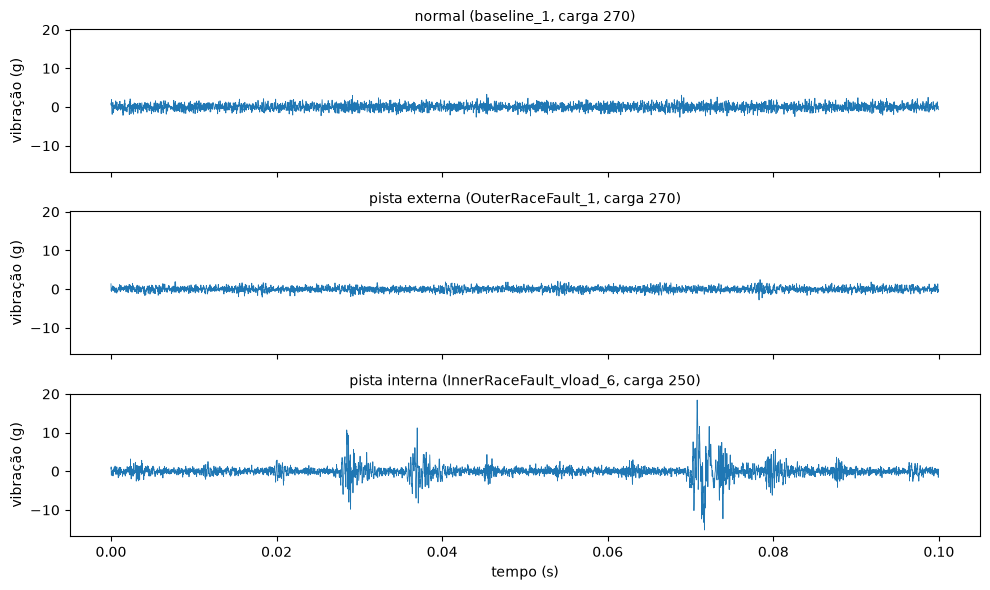

In [4]:
# Mostra 0,1 s de uma gravação de cada classe, na mesma escala, para ver a cara de cada defeito.
# Escolhemos gravações com carga 270 (ou a mais próxima, no caso da pista interna).
exemplos = ['baseline_1', 'OuterRaceFault_1', 'InnerRaceFault_vload_6']
n = int(0.1 * taxa)
t = np.arange(n) / taxa

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True, sharey=True)
for ax, nome in zip(axes, exemplos):
    linha = gravacoes.set_index('arquivo').loc[nome]
    ax.plot(t, linha.sinal[:n], lw=0.6)
    ax.set_title(f'{linha.classe} ({nome}, carga {linha.carga})', fontsize=10)
    ax.set_ylabel('vibração (g)')
axes[-1].set_xlabel('tempo (s)')
plt.tight_layout()
plt.show()

### Resultados

Ficamos com 78 segundos de sinal, todos com 48.828 medições por segundo: 18 s de rolamento normal (3 gravações), 39 s com defeito na pista externa (10 gravações) e 21 s com defeito na pista interna (7 gravações).

O deslocamento da média varia entre gravações: fica entre -0,06 e -0,14 nas gravações de 97.656, e muda aos poucos, arquivo após arquivo, nas de 48.828 (de -0,19 a -0,16 na pista externa e de -0,23 a -0,19 na pista interna). Isso é compatível com diferenças de aquisição, mas não prova sua origem. Retirar a média reduz uma pista possível para reconhecer a gravação, sem demonstrar que todas as diferenças de sessão foram eliminadas.

A pista interna se separa fácil: força média da vibração (rms) entre 1,73 e 2,07 g e picos de 23 a 46 g, contra 0,74 a 0,75 g e picos de 3,4 a 3,8 g no rolamento normal. No gráfico ela aparece como pancadas fortes e espaçadas, de até 18 g nesse trecho.

A pista externa é o caso difícil. Nas três gravações feitas nas mesmas condições do normal (carga 270, mesma taxa de gravação), a força média fica em 0,55, 0,68 e 0,87 g, uma abaixo e outra acima do normal, e os picos (3,3 a 5,1 g) também se misturam com os do normal. Nem a força média nem o pico, sozinhos, separam essas gravações. As outras sete têm picos maiores (5 a 19 g), mas não existe gravação normal com essas cargas para comparar.

Limites dos dados:
- só há 3 gravações normais, todas com carga 270, gravadas nas mesmas condições das três primeiras de pista externa;
- a pista interna nunca foi gravada nas mesmas condições do normal, então medidas genéricas do sinal (força média, pico) podem estar captando a sessão de gravação junto com o defeito;
- a comparação mais justa que os dados permitem é normal contra as três gravações de pista externa com carga 270.

## 2. O ritmo de cada defeito

Um defeito no rolamento causa uma pancada cada vez que uma esfera passa por ele. Com as medidas do rolamento que vêm no próprio dataset (8 esferas, diâmetro da esfera 0,235 e diâmetro do círculo das esferas 1,245) e a velocidade do eixo, dá para calcular quantas pancadas por segundo cada defeito produz (BECHHOEFER; MENON, 2009). Para enxergar esse ritmo, ficamos com a faixa de 2 a 4 mil ciclos por segundo do sinal, tiramos o contorno da vibração (a envoltória) e medimos quanto ele se repete em cada frequência, comparado com o fundo (KIM; AN; CHOI, 2020). A faixa de 2 a 4 mil ciclos por segundo é a que a MFPT usa no script de análise distribuído com os dados; ela não foi otimizada para este trabalho. As frequências previstas vêm da geometria e da velocidade do eixo. A coincidência dos picos com essas frequências reforça a interpretação de defeito, sem provar independência de carga, montagem ou sessão.

In [5]:
# Calcula o ritmo de pancadas de cada defeito pela geometria do rolamento e mede, em cada gravação,
# quanto o contorno da vibração se repete nesse ritmo, comparado com o fundo (de 50 a 200 Hz).
# Também mostra em que frequência fica o maior pico do contorno entre 50 e 200 Hz.
from scipy.signal import butter, sosfiltfilt, hilbert, welch

esfera, circulo, n_esferas = 0.235, 1.245, 8
razao = esfera / circulo
ritmo_externa = 0.5 * (1 - razao) * n_esferas
ritmo_interna = 0.5 * (1 + razao) * n_esferas

faixa = butter(4, [2000, 4000], btype='band', fs=taxa, output='sos')

def espectro_envoltoria(sinal):
    envoltoria = np.abs(hilbert(sosfiltfilt(faixa, sinal)))
    return welch(envoltoria - envoltoria.mean(), taxa, nperseg=2 ** 16)

def destaque(freq, potencia, alvo):
    perto = (freq > 0.97 * alvo) & (freq < 1.03 * alvo)
    fundo = np.median(potencia[(freq > 50) & (freq < 200)])
    return potencia[perto].max() / fundo

def frequencia_do_pico(freq, potencia):
    faixa_busca = (freq > 50) & (freq < 200)
    return freq[faixa_busca][np.argmax(potencia[faixa_busca])]

espectros = gravacoes.sinal.apply(espectro_envoltoria)
gravacoes['externa_x_fundo'] = [destaque(f, p, ritmo_externa * g)
                                for (f, p), g in zip(espectros, gravacoes.giro_hz)]
gravacoes['interna_x_fundo'] = [destaque(f, p, ritmo_interna * g)
                                for (f, p), g in zip(espectros, gravacoes.giro_hz)]
gravacoes['pico_hz'] = [frequencia_do_pico(f, p) for f, p in espectros]

print(f'pista externa: {ritmo_externa * 25:.1f} pancadas por segundo | '
      f'pista interna: {ritmo_interna * 25:.1f} pancadas por segundo (eixo a 25 voltas por segundo)')
gravacoes[['arquivo', 'classe', 'pico_hz', 'externa_x_fundo', 'interna_x_fundo']].round(1)

pista externa: 81.1 pancadas por segundo | pista interna: 118.9 pancadas por segundo (eixo a 25 voltas por segundo)


,arquivo,classe,pico_hz,externa_x_fundo,interna_x_fundo
0,baseline_1,normal,75.3,2.7,2.5
1,baseline_2,normal,120.0,1.6,4.1
2,baseline_3,normal,120.0,2.1,3.7
3,OuterRaceFault_1,pista externa,80.5,441.9,12.4
4,OuterRaceFault_2,pista externa,80.5,1020.9,9.1
5,OuterRaceFault_3,pista externa,80.5,1155.1,1.6
6,OuterRaceFault_vload_1,pista externa,79.7,422.8,2.2
7,OuterRaceFault_vload_2,pista externa,80.5,491.9,2.4
8,OuterRaceFault_vload_3,pista externa,80.5,534.4,2.1
9,OuterRaceFault_vload_4,pista externa,80.5,469.4,1.4


baseline_1: maior valor até 300 Hz = 2.44e-04
OuterRaceFault_1: maior valor até 300 Hz = 7.04e-03
InnerRaceFault_vload_6: maior valor até 300 Hz = 1.48e-01


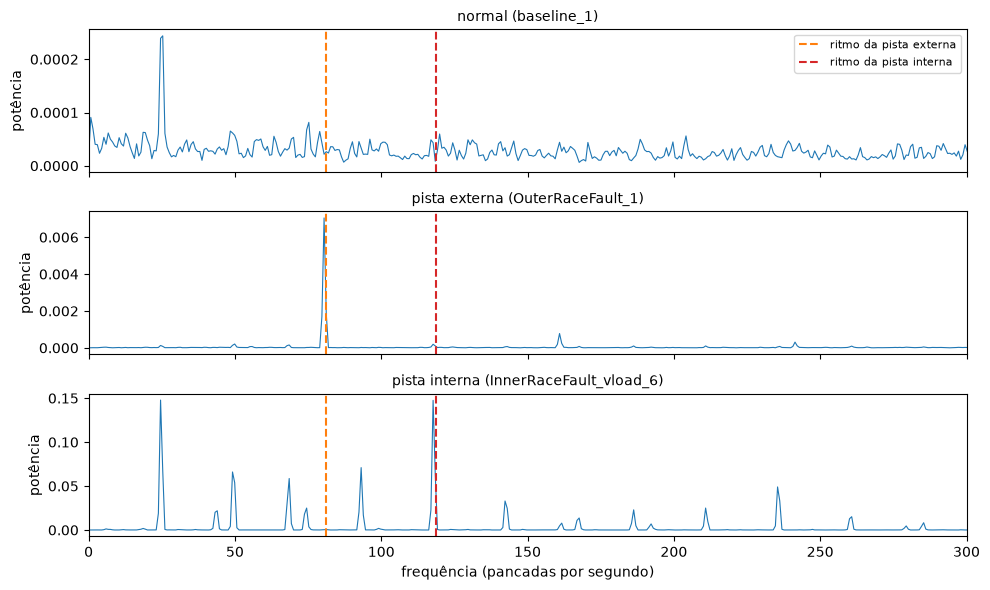

In [6]:
# Mostra o espectro do contorno das mesmas três gravações, com as linhas no ritmo esperado de cada
# defeito, e o maior valor de cada espectro até 300 Hz, já que os gráficos têm escalas diferentes.
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for ax, nome in zip(axes, exemplos):
    i = gravacoes.index[gravacoes.arquivo == nome][0]
    freq, potencia = espectros[i]
    ax.plot(freq, potencia, lw=0.8)
    ax.axvline(ritmo_externa * gravacoes.giro_hz[i], color='tab:orange', ls='--', label='ritmo da pista externa')
    ax.axvline(ritmo_interna * gravacoes.giro_hz[i], color='tab:red', ls='--', label='ritmo da pista interna')
    ax.set_title(f'{gravacoes.classe[i]} ({nome})', fontsize=10)
    ax.set_ylabel('potência')
    print(f'{nome}: maior valor até 300 Hz = {potencia[freq < 300].max():.2e}')
axes[0].legend(fontsize=8)
axes[-1].set_xlim(0, 300)
axes[-1].set_xlabel('frequência (pancadas por segundo)')
plt.tight_layout()
plt.show()

### Resultados

Pela geometria do rolamento, com o eixo a 25 voltas por segundo, o defeito na pista externa deveria causar 81,1 pancadas por segundo, e o da pista interna 118,9. É o que aparece. Nas 10 gravações de pista externa, o contorno da vibração se repete no ritmo da pista externa de 422,8 a 2.380,5 vezes mais do que o fundo. Nas 7 de pista interna, se repete no ritmo da pista interna de 1.301,0 a 1.996,9 vezes mais do que o fundo. Nas 3 normais, os dois ritmos ficam só de 1,6 a 4,1 vezes o fundo, ou seja, não aparecem. O maior pico do contorno entre 50 e 200 Hz cai em 80,5 Hz em 9 das 10 gravações de pista externa (79,7 Hz na outra) e em 117,7 Hz em todas as de pista interna, menos de 2% abaixo da conta, o que é compatível com o eixo girando um pouco abaixo de 25 voltas por segundo.

No gráfico do contorno, a pista externa mostra o pico no seu ritmo e um menor no dobro dele. A pista interna mostra o pico no seu ritmo e vários outros espaçados de 25 em 25, a velocidade do eixo, padrão descrito na literatura como típico de defeito na pista interna (KIM; AN; CHOI, 2020). Os três gráficos têm escalas diferentes: o maior valor até 300 Hz é 2,44e-04 na gravação normal e 1,48e-01 na de pista interna, cerca de 600 vezes maior.

A proximidade dos picos às frequências previstas pela geometria reforça a interpretação de defeito. O padrão também aparece nas três gravações de pista externa com a mesma carga e taxa nominais das normais, onde rms e pico se sobrepõem. Isso não demonstra independência de montagem, carga ou sessão: não houve um experimento controlado variando só o defeito.

## 3. Janelas e medidas

Para treinar e avaliar os modelos, cortamos cada gravação em janelas de 0,25 s e calculamos dois grupos de medidas para cada janela. As medidas genéricas olham o tamanho e o formato das pancadas: força média (rms), maior pico, curtose (o quanto o sinal é feito de pancadas isoladas) e pico dividido pela força média. As medidas do ritmo olham se o contorno da vibração se repete no ritmo de cada defeito.

Janelas vizinhas da mesma gravação são quase iguais: mesmo rolamento, mesma carga, mesma montagem. Se uma janela fica no treino e a vizinha na avaliação, o modelo pode acertar só por reconhecer a gravação (ROBERTS et al., 2017; KAPOOR; NARAYANAN, 2023). Por isso a avaliação principal deste trabalho separa gravações inteiras: uma gravação usada para avaliar nunca tem janelas no treino. As seções 4 e 5 descrevem cada etapa. A seção 5 também mostra uma comparação exploratória com janelas sorteadas, identificada separadamente.

In [7]:
# Corta cada gravação em janelas de 0,25 s e calcula as medidas de cada janela. As genéricas
# (força média, pico, curtose e pico dividido pela força média) olham só o tamanho e o formato das
# pancadas; as do ritmo olham se o contorno se repete no ritmo de cada defeito.
from scipy.stats import kurtosis

tamanho = int(0.25 * taxa)
genericas = ['rms', 'pico', 'curtose', 'pico_por_rms']
ritmo = ['externa_x_fundo', 'interna_x_fundo']

linhas = []
for _, g in gravacoes.iterrows():
    envoltoria = np.abs(hilbert(sosfiltfilt(faixa, g.sinal)))
    for k in range(len(g.sinal) // tamanho):
        trecho = slice(k * tamanho, (k + 1) * tamanho)
        s, e = g.sinal[trecho], envoltoria[trecho]
        freq, potencia = welch(e - e.mean(), taxa, nperseg=tamanho)
        rms = np.sqrt(np.mean(s ** 2))
        linhas.append({'arquivo': g.arquivo, 'classe': g.classe, 'carga': g.carga,
                       'rms': rms, 'pico': np.abs(s).max(), 'curtose': kurtosis(s),
                       'pico_por_rms': np.abs(s).max() / rms,
                       'externa_x_fundo': destaque(freq, potencia, ritmo_externa * g.giro_hz),
                       'interna_x_fundo': destaque(freq, potencia, ritmo_interna * g.giro_hz)})

janelas = pd.DataFrame(linhas)
print(janelas.groupby('classe').agg(gravacoes=('arquivo', 'nunique'), janelas=('arquivo', 'size')))
print()
print('ritmo do próprio defeito nas janelas (vezes o fundo):')
print(pd.DataFrame({
    'normal, ritmo externo': janelas.loc[janelas.classe == 'normal', 'externa_x_fundo'].describe(),
    'normal, ritmo interno': janelas.loc[janelas.classe == 'normal', 'interna_x_fundo'].describe(),
    'pista externa, ritmo externo': janelas.loc[janelas.classe == 'pista externa', 'externa_x_fundo'].describe(),
    'pista interna, ritmo interno': janelas.loc[janelas.classe == 'pista interna', 'interna_x_fundo'].describe(),
}).round(1).loc[['min', '50%', 'max']])

               gravacoes  janelas
classe                           
normal                 3       72
pista externa         10      156
pista interna          7       84

ritmo do próprio defeito nas janelas (vezes o fundo):
     normal, ritmo externo  normal, ritmo interno  \
min                    0.0                    0.4   
50%                    1.0                    2.1   
max                    5.3                   11.6   

     pista externa, ritmo externo  pista interna, ritmo interno  
min                          27.8                           9.0  
50%                         116.5                          20.5  
max                         403.6                          81.0  


### Resultados

Foram 312 janelas: 72 normais (3 gravações), 156 de pista externa (10 gravações) e 84 de pista interna (7 gravações).

Numa janela de 0,25 s o ritmo do defeito aparece bem mais fraco do que na gravação inteira, porque a janela curta tem menos pancadas para medir. Nas janelas de pista externa, o ritmo da pista externa fica entre 27,8 e 403,6 vezes o fundo (mediana de 116,5). Nas de pista interna, o ritmo da pista interna fica entre 9,0 e 81,0 vezes o fundo (mediana de 20,5). Nas janelas normais, os dois ritmos chegam no máximo a 5,3 e 11,6 vezes o fundo. Janelas mais longas deixariam o ritmo mais claro, mas dariam menos janelas normais para treinar.

## 4. Detecção

Na detecção, o modelo aprende apenas com janelas normais e não sabe que tipos de defeito existem; ele só aprende como é o normal. Usamos duas técnicas. O Isolation Forest faz cortes ao acaso nos dados: uma janela que fica isolada com poucos cortes é diferente das demais (LIU; TING; ZHOU, 2008). A distância com PCA mede quantos desvios-padrão do normal uma janela está, nas direções principais dos dados normais, usando coordenadas com variância unitária (whitening; JOLLIFFE; CADIMA, 2016; documentação do scikit-learn). Aqui mantemos todos os componentes: a norma dessas coordenadas corresponde à distância de Mahalanobis estimada no treino quando a covariância tem posto completo. Não é a redução de dimensionalidade testada no diagnóstico, nem uma implementação do controle dinâmico de Pérez-Torres et al. (2026). Cada técnica roda duas vezes, uma com cada grupo de medidas.

A avaliação deixa uma gravação normal inteira de fora a cada rodada. Como há 3 gravações normais, são 3 rodadas: o detector aprende com as janelas das outras duas, o alarme falso (FPR) é medido nas janelas da gravação normal que ficou de fora, e a detecção (TPR) em todas as janelas com defeito. O detector nunca viu nenhuma das janelas avaliadas. O limite de alerta é a janela normal mais estranha do treino da rodada: o que passar dela é anomalia. Esse limite foi escolhido antes de olhar os resultados, para não ajustá-lo aos dados avaliados.

In [8]:
# Detecção avaliada deixando uma gravação normal inteira de fora a cada rodada (3 rodadas). O detector
# aprende só com as janelas das outras duas gravações normais e não sabe que defeitos existem; o
# limite de alerta é a janela normal mais estranha desse treino. O alarme falso (FPR) é medido na
# gravação normal que ficou de fora e a detecção (TPR) em todas as janelas com defeito: o detector
# nunca viu nenhuma delas. O Isolation Forest isola as janelas com cortes ao acaso (o que fica
# isolado rápido é estranho); a distância com PCA mede quantos desvios-padrão do normal a janela está.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

def estranheza_isolation(treino, avaliado):
    modelo = IsolationForest(random_state=42).fit(treino)
    return -modelo.score_samples(treino), -modelo.score_samples(avaliado)

def estranheza_pca(treino, avaliado):
    scaler = StandardScaler().fit(treino)
    pca = PCA(whiten=True).fit(scaler.transform(treino))
    distancia = lambda X: np.linalg.norm(pca.transform(scaler.transform(X)), axis=1)
    return distancia(treino), distancia(avaliado)

janelas['grupo'] = np.where((janelas.classe == 'pista externa') & (janelas.carga == 270),
                            'pista externa, carga 270', janelas.classe)
normais = sorted(gravacoes.arquivo[gravacoes.classe == 'normal'])
tecnicas = {'Isolation Forest': estranheza_isolation, 'Distância com PCA': estranheza_pca}
grupos_medidas = {'genéricas': genericas, 'ritmo do defeito': ritmo}

rodadas_deteccao, alertas = [], []
for tecnica, estranheza in tecnicas.items():
    for nome_medidas, colunas in grupos_medidas.items():
        for fora in normais:
            treino_normal = janelas[(janelas.classe == 'normal') & (janelas.arquivo != fora)]
            avaliado = janelas[(janelas.arquivo == fora) | (janelas.classe != 'normal')].copy()
            nota_treino, nota = estranheza(treino_normal[colunas], avaliado[colunas])
            avaliado['alerta'] = nota > nota_treino.max()
            avaliado['tecnica'], avaliado['medidas'], avaliado['normal_fora'] = tecnica, nome_medidas, fora
            defeito = avaliado.classe != 'normal'
            rodadas_deteccao.append({'técnica': tecnica, 'medidas': nome_medidas, 'normal deixada de fora': fora,
                                     'TPR': avaliado.alerta[defeito].mean(), 'FPR': avaliado.alerta[~defeito].mean()})
            alertas.append(avaliado)

rodadas_deteccao = pd.DataFrame(rodadas_deteccao)
alertas = pd.concat(alertas)
print(rodadas_deteccao.round(3).to_string(index=False))
deteccao = rodadas_deteccao.groupby(['técnica', 'medidas'], sort=False)[['TPR', 'FPR']].mean()
deteccao.round(3)

          técnica          medidas normal deixada de fora   TPR   FPR
 Isolation Forest        genéricas             baseline_1 0.942 0.042
 Isolation Forest        genéricas             baseline_2 0.842 0.000
 Isolation Forest        genéricas             baseline_3 0.883 0.000
 Isolation Forest ritmo do defeito             baseline_1 0.133 0.000
 Isolation Forest ritmo do defeito             baseline_2 0.088 0.000
 Isolation Forest ritmo do defeito             baseline_3 0.100 0.000
Distância com PCA        genéricas             baseline_1 1.000 0.042
Distância com PCA        genéricas             baseline_2 1.000 0.000
Distância com PCA        genéricas             baseline_3 1.000 0.000
Distância com PCA ritmo do defeito             baseline_1 0.988 0.000
Distância com PCA ritmo do defeito             baseline_2 0.996 0.083
Distância com PCA ritmo do defeito             baseline_3 0.988 0.000


TPR    FPR
técnica           medidas                       
Isolation Forest  genéricas         0.889  0.014
                  ritmo do defeito  0.107  0.000
Distância com PCA genéricas         1.000  0.014
                  ritmo do defeito  0.990  0.028

In [9]:
# Quanto cada combinação detecta em cada grupo de gravações, na média das 3 rodadas. O grupo que
# importa é a pista externa com carga 270, gravada nas mesmas condições do normal. Para a distância
# com PCA com as medidas do ritmo, lista as janelas com defeito que não geraram alerta.
print(alertas.groupby(['tecnica', 'medidas', 'grupo'], sort=False).alerta.mean().unstack().round(3).to_string())
print()
perdidas = alertas[(alertas.tecnica == 'Distância com PCA') & (alertas.medidas == 'ritmo do defeito')
                   & (alertas.classe != 'normal') & ~alertas.alerta]
print('janelas com defeito sem alerta (distância com PCA, ritmo do defeito):')
print(perdidas[['normal_fora', 'arquivo', 'carga', 'externa_x_fundo', 'interna_x_fundo']].round(1).to_string())
print()
print('maior ritmo interno numa janela normal:', janelas.loc[janelas.classe == 'normal', 'interna_x_fundo'].max().round(1))

grupo                               normal  pista externa, carga 270  pista externa  pista interna
tecnica           medidas                                                                         
Isolation Forest  genéricas          0.014                     0.630            1.0          1.000
                  ritmo do defeito   0.000                     0.005            0.0          0.302
Distância com PCA genéricas          0.014                     1.000            1.0          1.000
                  ritmo do defeito   0.028                     1.000            1.0          0.972

janelas com defeito sem alerta (distância com PCA, ritmo do defeito):
    normal_fora                 arquivo  carga  externa_x_fundo  interna_x_fundo
283  baseline_1  InnerRaceFault_vload_5    200              0.2             10.5
285  baseline_1  InnerRaceFault_vload_5    200              0.2              9.0
286  baseline_1  InnerRaceFault_vload_5    200              0.2             11.1
285  baseli

### Resultados

Média das 3 rodadas:

| Técnica | Medidas | Detecta defeito (TPR) | Alarme falso (FPR) | Pista externa, carga 270 | Pista interna |
|---|---|---|---|---|---|
| Isolation Forest | genéricas | 0,889 | 0,014 | 0,630 | 1,000 |
| Isolation Forest | ritmo do defeito | 0,107 | 0,000 | 0,005 | 0,302 |
| Distância com PCA | genéricas | 1,000 | 0,014 | 1,000 | 1,000 |
| Distância com PCA | ritmo do defeito | 0,990 | 0,028 | 1,000 | 0,972 |

A distância com PCA funcionou com os dois grupos de medidas. Com as medidas do ritmo, detectou 99,0% das janelas com defeito, todas as de pista externa. As únicas janelas que ela deixou passar são da gravação de pista interna com carga 200, em que o ritmo da pista interna ficou entre 9,0 e 11,1 vezes o fundo, abaixo da janela normal com o ritmo mais alto por acaso (11,6). O alarme falso dela foi de 0 nas rodadas sem a baseline_1 e sem a baseline_3, e de 8,3% (2 de 24 janelas) na rodada sem a baseline_2. Com as medidas genéricas, detectou todas as janelas com defeito, com 1 alarme falso (4,2% das janelas da baseline_1) e nenhum nas outras rodadas. Combinando as quatro medidas genéricas, a distância com PCA separou do normal também as janelas de pista externa com carga 270, embora a força média e o pico sozinhos não separem essas gravações.

O Isolation Forest falhou com as medidas do ritmo, detectando só 10,7% dos defeitos. Uma explicação compatível com o resultado é a combinação entre a pontuação e o limiar usado: os cortes são feitos entre o menor e o maior valor de cada medida no treino (LIU; TING; ZHOU, 2008), e valores muito além dessa faixa podem receber pontuações semelhantes. O limiar é a janela normal mais extrema do treino. Não isolamos esse mecanismo nem comparamos aqui as distribuições de pontuação; portanto, ele permanece uma hipótese para a baixa detecção observada. Com as medidas genéricas ele foi melhor (88,9%, com 1,4% de alarme falso), mas detectou só 63,0% das janelas de pista externa com carga 270, o caso mais difícil.

Cada rodada mede o alarme falso numa única gravação normal (24 janelas). Com só 3 gravações normais, essas taxas são pouco precisas: uma janela a mais com alerta muda o alarme falso da rodada em 4,2 pontos percentuais.

## 5. Diagnóstico

No diagnóstico, o modelo aprende com as três classes e precisa dizer qual é o defeito de cada janela. Usamos os seguintes modelos: regressão logística, Knn, árvore de decisão e Random Forest, cada um com os dois grupos de medidas, (SPERANDEI, 2014; COVER; HART, 1967; QUINLAN, 1986; BREIMAN, 2001), todos com a implementação do scikit-learn (PEDREGOSA et al., 2011).

Primeiro comparamos duas formas de validação cruzada. Na comum, as janelas são sorteadas entre as rodadas, então quase sempre uma janela cai no treino e a vizinha na avaliação. Na separada por gravação, cada gravação fica inteira de um lado só. São 3 rodadas, e cada uma deixa de fora uma das 3 gravações normais e cerca de um terço das gravações de cada defeito. A diferença é um diagnóstico de possível otimismo por dependência entre janelas, não uma medida causal desse efeito. Também mudam a composição e a quantidade de exemplos de treino; usamos o mesmo número de folds nas duas comparações.

A avaliação final também é por gravação. Em cada uma das 3 rodadas, as gravações da rodada ficam de fora; com as demais, o melhor modelo é escolhido por validação separada por gravação, treinado e usado para classificar as gravações de fora. Assim a escolha do modelo nunca vê as gravações em que ele é avaliado. Juntando as 3 rodadas, cada janela é classificada uma vez, por um modelo que não viu a gravação dela, e daí saem a matriz de confusão e o acerto por classe.

Também testamos o PCA para resumir as medidas em poucos componentes antes do classificador. Juntamos as 6 medidas, padronizamos e ficamos com os componentes que somam 70% da variação, um corte comum na prática (JOLLIFFE; CADIMA, 2016), e, para comparar, 90%. Comparamos com as 6 medidas juntas sem PCA, pela validação separada por gravação.

Comparamos uma fronteira linear (logística), vizinhança local (Knn), regras de corte (árvore) e
um conjunto de árvores (Random Forest), sem busca adicional de hiperparâmetros. Logística e
Knn recebem escala; árvore e floresta não dependem da mesma distância entre atributos.
O Knn pode ser sensível a pontos próximos da mesma gravação; a árvore pode ajustar demais;
a floresta reduz essa instabilidade, mas não resolve diferenças de aquisição.
As bases e limitações estão em Sperandei (2014), Cover e Hart (1967), Quinlan (1986) e
Breiman (2001), acompanhadas das respectivas seções da documentação do scikit-learn na seção 8.

In [10]:
# Compara a validação cruzada comum (janelas sorteadas) com a separada por gravação, para cada
# modelo e grupo de medidas. A diferença indica possível otimismo por dependência entre
# janelas, mas não isola sua causa. As 3 rodadas da separada por gravação são montadas no código: dentro de cada
# classe, as gravações são distribuídas em ordem entre as rodadas, então cada rodada deixa de fora
# uma gravação normal e cerca de um terço das gravações de cada defeito.
from sklearn.base import clone
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

def montar_rodadas(seed=None):
    rng = np.random.default_rng(seed)
    rodada_da_gravacao = {}
    for classe, arquivos_classe in gravacoes.groupby('classe').arquivo:
        nomes = sorted(arquivos_classe)
        if seed is not None:
            nomes = rng.permutation(nomes)
        rodada_da_gravacao.update({nome: k % 3 for k, nome in enumerate(nomes)})
    return janelas.arquivo.map(rodada_da_gravacao)

rodada = montar_rodadas()
rodadas_por_gravacao = [(np.where(rodada != r)[0], np.where(rodada == r)[0]) for r in range(3)]

models = {'Regressão logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          'Knn (k=3)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)),
          'Árvore de decisão': DecisionTreeClassifier(random_state=42),
          'Random Forest': RandomForestClassifier(random_state=42)}

cv_results = []
for nome_medidas, colunas in grupos_medidas.items():
    for nome_modelo, model in models.items():
        comum = cross_val_score(model, janelas[colunas], janelas.classe,
                                cv=KFold(3, shuffle=True, random_state=42), scoring='accuracy').mean()
        por_gravacao = cross_val_score(model, janelas[colunas], janelas.classe, cv=rodadas_por_gravacao,
                                       scoring='accuracy').mean()
        cv_results.append({'medidas': nome_medidas, 'modelo': nome_modelo,
                           'validação comum': comum, 'separando por gravação': por_gravacao,
                           'diferença': por_gravacao - comum})

cv_results = pd.DataFrame(cv_results)
cv_results.round(3)

,medidas,modelo,validação comum,separando por gravação,diferença
0,genéricas,Regressão logística,0.958,0.909,-0.049
1,genéricas,Knn (k=3),0.997,0.892,-0.105
2,genéricas,Árvore de decisão,1.000,0.900,-0.100
3,genéricas,Random Forest,1.000,0.914,-0.086
4,ritmo do defeito,Regressão logística,0.990,0.987,-0.003
5,ritmo do defeito,Knn (k=3),0.990,0.990,-0.001
6,ritmo do defeito,Árvore de decisão,0.987,0.990,0.002
7,ritmo do defeito,Random Forest,0.990,0.986,-0.004


In [11]:
# Avaliação final do diagnóstico, também por gravação: em cada uma das 3 rodadas, as gravações da
# rodada ficam de fora; com as outras, o melhor modelo é escolhido por validação separada por
# gravação (2 rodadas internas), treinado e usado para classificar as gravações de fora. Assim a
# escolha do modelo nunca vê as gravações em que ele é avaliado. Juntando as 3 rodadas, cada janela
# é classificada uma vez, por um modelo que não viu a gravação dela.
def diagnostico_por_gravacao(colunas, rodada_avaliacao=None):
    if rodada_avaliacao is None:
        rodada_avaliacao = rodada
    previsto = pd.Series(index=janelas.index, dtype=object)
    escolhidos = []
    for r in range(3):
        fora = (rodada_avaliacao == r).to_numpy()
        treino, rodada_treino = janelas[~fora], rodada_avaliacao[~fora]
        assert set(treino.arquivo).isdisjoint(janelas.loc[fora, 'arquivo'])
        assert set(treino.classe) == set(janelas.classe)
        internas = [(np.where(rodada_treino != q)[0], np.where(rodada_treino == q)[0])
                    for q in sorted(rodada_treino.unique())]
        for treino_i, valid_i in internas:
            assert set(treino.iloc[treino_i].arquivo).isdisjoint(treino.iloc[valid_i].arquivo)
            assert set(treino.iloc[treino_i].classe) == set(janelas.classe)
        notas = {nome: cross_val_score(model, treino[colunas], treino.classe, cv=internas,
                                       scoring='accuracy').mean() for nome, model in models.items()}
        melhor = max(notas, key=notas.get)
        model = clone(models[melhor]).fit(treino[colunas], treino.classe)
        previsto[fora] = model.predict(janelas.loc[fora, colunas])
        escolhidos.append(melhor)
    assert previsto.notna().all()
    return previsto, escolhidos

finais = {}
for nome_medidas, colunas in grupos_medidas.items():
    previsto, escolhidos = diagnostico_por_gravacao(colunas)
    finais[nome_medidas] = (previsto, escolhidos)
    certo = previsto == janelas.classe
    print(f'== medidas {nome_medidas}: modelo escolhido em cada rodada: {escolhidos} ==')
    print(classification_report(janelas.classe, previsto, digits=3))
    print('acerto por classe:', certo.groupby(janelas.classe).mean().round(3).to_dict())
    print(f'acerto na pista externa com carga 270: {certo[janelas.grupo == "pista externa, carga 270"].mean():.3f}')
    erros = janelas[~certo].assign(previsto=previsto[~certo])
    print('janelas erradas por gravação:', erros.groupby(['arquivo', 'previsto']).size().to_dict())
    print()

== medidas genéricas: modelo escolhido em cada rodada: ['Regressão logística', 'Random Forest', 'Regressão logística'] ==
               precision    recall  f1-score   support

       normal      0.825     0.917     0.868        72
pista externa      0.957     0.859     0.905       156
pista interna      0.913     1.000     0.955        84

     accuracy                          0.910       312
    macro avg      0.898     0.925     0.909       312
 weighted avg      0.915     0.910     0.910       312

acerto por classe: {'normal': 0.917, 'pista externa': 0.859, 'pista interna': 1.0}
acerto na pista externa com carga 270: 0.806
janelas erradas por gravação: {('OuterRaceFault_1', 'normal'): 14, ('OuterRaceFault_vload_7', 'pista interna'): 8, ('baseline_1', 'pista externa'): 2, ('baseline_3', 'pista externa'): 4}



== medidas ritmo do defeito: modelo escolhido em cada rodada: ['Knn (k=3)', 'Knn (k=3)', 'Knn (k=3)'] ==
               precision    recall  f1-score   support

       normal      0.986     0.972     0.979        72
pista externa      1.000     1.000     1.000       156
pista interna      0.976     0.988     0.982        84

     accuracy                          0.990       312
    macro avg      0.987     0.987     0.987       312
 weighted avg      0.990     0.990     0.990       312

acerto por classe: {'normal': 0.972, 'pista externa': 1.0, 'pista interna': 0.988}
acerto na pista externa com carga 270: 1.000
janelas erradas por gravação: {('InnerRaceFault_vload_5', 'normal'): 1, ('baseline_2', 'pista interna'): 1, ('baseline_3', 'pista interna'): 1}



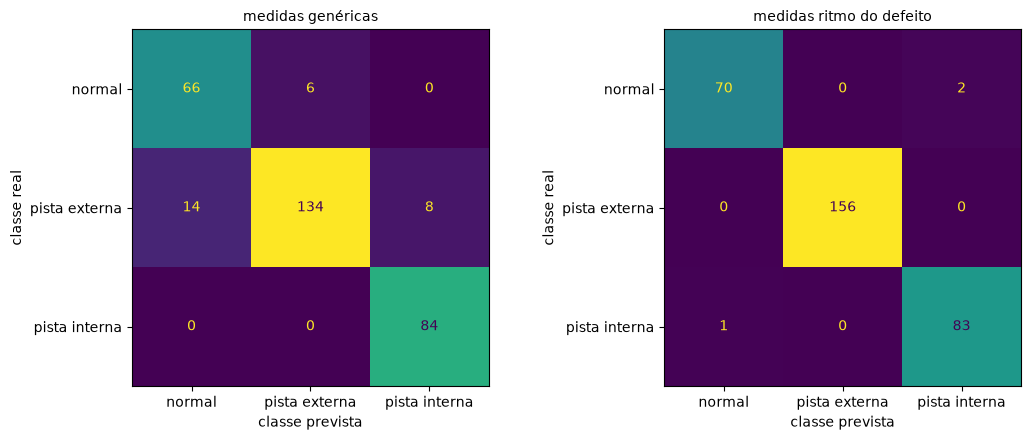

In [12]:
# Matriz de confusão de cada grupo de medidas, com todas as classes e todas as janelas.
classes_ordem = ['normal', 'pista externa', 'pista interna']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nome_medidas, (previsto, escolhidos)) in zip(axes, finais.items()):
    cm = confusion_matrix(janelas.classe, previsto, labels=classes_ordem)
    ConfusionMatrixDisplay(cm, display_labels=classes_ordem).plot(ax=ax, colorbar=False)
    ax.set_title(f'medidas {nome_medidas}', fontsize=10)
    ax.set_xlabel('classe prevista')
    ax.set_ylabel('classe real')
plt.tight_layout()
plt.show()

In [13]:
# Testa o PCA antes do classificador: as 6 medidas juntas, padronizadas e resumidas nos componentes
# que somam 70% ou 90% da variação. O PCA é ajustado só com o treino de cada rodada, por isso fica
# dentro do pipeline. Compara com as 6 medidas juntas sem PCA, pela validação separada por gravação.
todas = genericas + ritmo
pca_results = []
for nome_entrada, variacao in [('6 medidas, sem PCA', None), ('PCA, 70% da variação', 0.7), ('PCA, 90% da variação', 0.9)]:
    for nome_modelo, model in models.items():
        if variacao:
            model = make_pipeline(StandardScaler(), PCA(variacao), clone(model))
        acerto = cross_val_score(model, janelas[todas], janelas.classe, cv=rodadas_por_gravacao,
                                 scoring='accuracy').mean()
        pca_results.append({'entrada': nome_entrada, 'modelo': nome_modelo, 'separando por gravação': acerto})

pca = PCA().fit(StandardScaler().fit_transform(janelas[todas]))
print('variação explicada por componente:', pca.explained_variance_ratio_.round(3))
pd.DataFrame(pca_results).pivot(index='entrada', columns='modelo', values='separando por gravação').round(3)

variação explicada por componente: [0.776 0.141 0.056 0.021 0.006 0.001]


modelo,Knn (k=3),Random Forest,Regressão logística,Árvore de decisão
entrada,,,,
"6 medidas, sem PCA",0.992,0.992,0.972,1.000
"PCA, 70% da variação",0.821,0.813,0.767,0.813
"PCA, 90% da variação",0.994,0.997,0.975,0.994


### Resultados

A tabela executada acima compara três folds de janelas sorteadas com três folds de gravações
inteiras. Uma queda ao separar gravações é compatível com otimismo por dependência entre
janelas; não permite atribuir toda a diferença a reconhecer a sessão. A comparação continua
sujeita à composição das partições. Comparamos os mesmos modelos e grupos de medidas.

Na avaliação final, a unidade separada entre treino e avaliação é a gravação; os acertos abaixo
são **frações de janelas**, e não frações de gravações classificadas corretamente.

Na avaliação final por gravação:

| Medidas | Modelo escolhido nas 3 rodadas | Acerto geral | Normal | Pista externa | Pista interna | Pista externa, carga 270 |
|---|---|---|---|---|---|---|
| genéricas | regressão logística, Random Forest, regressão logística | 0,910 | 0,917 | 0,859 | 1,000 | 0,806 |
| ritmo do defeito | Knn (k=3) nas três | 0,990 | 0,972 | 1,000 | 0,988 | 1,000 |

Com as medidas genéricas, os erros se concentram onde o normal e a pista externa se parecem: 14 janelas da OuterRaceFault_1 (carga 270, a de menor força média) foram classificadas como normais, e 6 janelas normais (2 da baseline_1 e 4 da baseline_3) como pista externa. Outras 8 janelas da OuterRaceFault_vload_7 (carga 300) foram classificadas como pista interna. Com as medidas do ritmo, houve 3 erros em 312 janelas: uma janela da gravação de pista interna com carga 200 classificada como normal, a mesma gravação fraca da detecção, e uma janela da baseline_2 e outra da baseline_3 classificadas como pista interna.

O teste com PCA, pela validação separada por gravação:

| Entrada | Regressão logística | Knn (k=3) | Árvore de decisão | Random Forest |
|---|---|---|---|---|
| 6 medidas, sem PCA | 0,972 | 0,992 | 1,000 | 0,992 |
| PCA, 70% da variação (1 componente) | 0,767 | 0,821 | 0,813 | 0,813 |
| PCA, 90% da variação (2 componentes) | 0,975 | 0,994 | 0,994 | 0,997 |

Com o corte de 70% da variação, o PCA piorou o diagnóstico: o primeiro componente sozinho já explica 77,6% da variação, então só ele fica, e o acerto cai para 76,7% a 82,1%. O PCA guarda as direções em que os dados mais variam, mas não usa as classes. Isso é compatível com a perda de informação discriminante ao reter só a direção de maior variância; a variância explicada, sozinha, não identifica qual efeito físico causou a perda. Com 90% da variação ficam 2 componentes, e o resultado volta a ser o mesmo das 6 medidas sem PCA. Com tão poucas medidas, comprimir não trouxe ganho. Juntar as 6 medidas deu resultado parecido com o de usar só as do ritmo (de 97,2% a 100%, contra 98,6% a 99,0%).

### Resultados por gravação

Cada linha abaixo representa um arquivo, com classe, carga e número de janelas. Nas colunas de
detecção, a fração com alerta é **FPR nas normais** e **TPR nas falhas**; nas falhas, calculamos
primeiro a média das três rodadas de treino normal, sem contá-las como novos arquivos.
As colunas de diagnóstico são acurácias **das janelas daquele arquivo**, previstas fora do treino;
não são voto majoritário. A síntese seguinte dá peso igual a cada arquivo, de modo que os de
seis segundos não dominem os de três. Mostramos as três normais, sem supor que sejam uma
amostra suficiente de todas as condições normais de operação.

In [14]:
# Reúne as previsões já feitas; nenhum modelo novo é treinado nesta tabela.
taxas_alerta = (alertas.groupby(['tecnica', 'medidas', 'arquivo', 'classe', 'carga'])
               .alerta.mean().rename('fracao_alerta').reset_index())
por_gravacao = (janelas.groupby(['arquivo', 'classe', 'carga']).size().rename('janelas').to_frame())
for (tecnica, medidas), parte in taxas_alerta.groupby(['tecnica', 'medidas']):
    nome = f'{tecnica} | {medidas}'
    por_gravacao[nome] = parte.set_index(['arquivo', 'classe', 'carga']).fracao_alerta
for medidas, (previsto, _) in finais.items():
    por_gravacao[f'acerto diagnostico | {medidas}'] = (janelas.assign(certo=previsto == janelas.classe)
        .groupby(['arquivo', 'classe', 'carga']).certo.mean())
assert len(por_gravacao) == len(gravacoes)
display(por_gravacao.round(3))

# Média de taxas por arquivo, mantendo distintas as unidades de análise.
resumo_arquivos = []
for (tecnica, medidas), parte in taxas_alerta.groupby(['tecnica', 'medidas']):
    normal = parte.classe == 'normal'
    resumo_arquivos.append({'tecnica': tecnica, 'medidas': medidas,
        'TPR medio por arquivo': parte.loc[~normal, 'fracao_alerta'].mean(),
        'FPR medio por arquivo': parte.loc[normal, 'fracao_alerta'].mean()})
print('Detecção: peso igual por arquivo, sem voto majoritário')
display(pd.DataFrame(resumo_arquivos).round(3))
print('FPR em cada uma das três gravações normais')
display(por_gravacao.xs('normal', level='classe').iloc[:, 1:5].round(3))
print('Diagnóstico: média das acurácias por arquivo, agrupadas por classe')
acertos_arquivos = por_gravacao.filter(like='acerto diagnostico')
display(acertos_arquivos.groupby(level='classe').mean().round(3))


,,,janelas,Distância com PCA | genéricas,Distância com PCA | ritmo do defeito,Isolation Forest | genéricas,Isolation Forest | ritmo do defeito,acerto diagnostico | genéricas,acerto diagnostico | ritmo do defeito
arquivo,classe,carga,,,,,,,
InnerRaceFault_vload_1,pista interna,0,12,1.000,1.000,1.000,0.333,1.000,1.000
InnerRaceFault_vload_2,pista interna,50,12,1.000,1.000,1.000,0.611,1.000,1.000
InnerRaceFault_vload_3,pista interna,100,12,1.000,1.000,1.000,0.306,1.000,1.000
InnerRaceFault_vload_4,pista interna,150,12,1.000,1.000,1.000,0.361,1.000,1.000
InnerRaceFault_vload_5,pista interna,200,12,1.000,0.806,1.000,0.194,1.000,0.917
InnerRaceFault_vload_6,pista interna,250,12,1.000,1.000,1.000,0.000,1.000,1.000
InnerRaceFault_vload_7,pista interna,300,12,1.000,1.000,1.000,0.306,1.000,1.000
OuterRaceFault_1,pista externa,270,24,1.000,1.000,0.542,0.014,0.417,1.000
OuterRaceFault_2,pista externa,270,24,1.000,1.000,0.347,0.000,1.000,1.000


Detecção: peso igual por arquivo, sem voto majoritário


,tecnica,medidas,TPR medio por arquivo,FPR medio por arquivo
0,Distância com PCA,genéricas,1.000,0.014
1,Distância com PCA,ritmo do defeito,0.989,0.028
2,Isolation Forest,genéricas,0.935,0.014
3,Isolation Forest,ritmo do defeito,0.125,0.000


FPR em cada uma das três gravações normais


,,Distância com PCA | genéricas,Distância com PCA | ritmo do defeito,Isolation Forest | genéricas,Isolation Forest | ritmo do defeito
arquivo,carga,,,,
baseline_1,270,0.042,0.000,0.042,0.0
baseline_2,270,0.000,0.083,0.000,0.0
baseline_3,270,0.000,0.000,0.000,0.0


Diagnóstico: média das acurácias por arquivo, agrupadas por classe


,acerto diagnostico | genéricas,acerto diagnostico | ritmo do defeito
classe,,
normal,0.917,0.972
pista externa,0.875,1.000
pista interna,1.000,0.988


### Sensibilidade à divisão das gravações

Mantemos a avaliação principal anterior e acrescentamos cinco divisões fixadas antes desta
execução (seeds 11, 23, 37, 51 e 79). Em cada divisão, distribuímos arquivos inteiros de cada
classe em três folds; cada normal aparece uma vez na avaliação. Repetimos a mesma seleção
interna dos quatro classificadores, separadamente para os dois grupos de medidas. Não
escolhemos o melhor seed nem mudamos modelos ou features conforme o resultado.

A faixa mínimo–máximo descreve **sensibilidade à partição**, não é intervalo de confiança.
As divisões reutilizam as mesmas gravações e seus resultados não são ensaios independentes.
Esta é validação interna adicional após exploração do conjunto, não um novo teste externo.

In [15]:
# Cinco divisões previamente fixadas, com os mesmos modelos e seleção aninhada.
seeds_sensibilidade = [11, 23, 37, 51, 79]
sensibilidade = []
for seed in seeds_sensibilidade:
    rodada_seed = montar_rodadas(seed)
    assert (janelas.assign(fold=rodada_seed).groupby('arquivo').fold.nunique() == 1).all()
    for medidas, colunas in grupos_medidas.items():
        previsto, escolhidos = diagnostico_por_gravacao(colunas, rodada_seed)
        acerto_arquivo = (janelas.assign(certo=previsto == janelas.classe)
                         .groupby('arquivo').certo.mean())
        sensibilidade.append({'seed': seed, 'medidas': medidas,
            'acerto por janela': (previsto == janelas.classe).mean(),
            'media do acerto por arquivo': acerto_arquivo.mean(),
            'menor acerto de um arquivo': acerto_arquivo.min(),
            'modelos nos tres folds': ' / '.join(escolhidos)})
sensibilidade = pd.DataFrame(sensibilidade)
display(sensibilidade.round(3))
print('Sensibilidade à divisão; faixa descritiva, não intervalo de confiança')
faixa_sensibilidade = sensibilidade.groupby('medidas')[['acerto por janela', 'media do acerto por arquivo']].agg(['min', 'max'])
display(faixa_sensibilidade.round(3))

resumo_faixas = sensibilidade.groupby('medidas')['acerto por janela'].agg(['min', 'max'])
g, r = resumo_faixas.loc['genéricas'], resumo_faixas.loc['ritmo do defeito']
display(Markdown(
    f"Nas cinco divisões, o acerto por janela das medidas genéricas variou de **{g['min']:.1%} a {g['max']:.1%}**; "
    f"o das medidas do ritmo variou de **{r['min']:.1%} a {r['max']:.1%}**. "
    "Neste conjunto, as medidas do ritmo foram menos sensíveis à composição dos folds. "
    "A faixa descreve somente as divisões avaliadas; não é intervalo de confiança nem demonstra "
    "generalização para novas máquinas ou sessões. Nenhuma divisão foi escolhida como novo resultado principal."
))


,seed,medidas,acerto por janela,media do acerto por arquivo,menor acerto de um arquivo,modelos nos tres folds
0,11,genéricas,0.952,0.946,0.083,Random Forest / Knn (k=3) / Regressão logística
1,11,ritmo do defeito,0.994,0.994,0.917,Árvore de decisão / Knn (k=3) / Knn (k=3)
2,23,genéricas,0.888,0.912,0.000,Random Forest / Regressão logística / Random F...
3,23,ritmo do defeito,0.987,0.988,0.833,Knn (k=3) / Knn (k=3) / Knn (k=3)
4,37,genéricas,0.872,0.892,0.000,Árvore de decisão / Regressão logística / Rand...
5,37,ritmo do defeito,0.990,0.992,0.917,Knn (k=3) / Árvore de decisão / Knn (k=3)
6,51,genéricas,0.788,0.838,0.000,Knn (k=3) / Regressão logística / Random Forest
7,51,ritmo do defeito,0.987,0.988,0.833,Árvore de decisão / Knn (k=3) / Árvore de decisão
8,79,genéricas,0.811,0.854,0.000,Regressão logística / Árvore de decisão / Rand...
9,79,ritmo do defeito,0.994,0.994,0.917,Knn (k=3) / Knn (k=3) / Knn (k=3)


Sensibilidade à divisão; faixa descritiva, não intervalo de confiança


acerto por janela        media do acerto por arquivo       
                               min    max                         min    max
medidas                                                                     
genéricas                    0.788  0.952                       0.838  0.946
ritmo do defeito             0.987  0.994                       0.988  0.994

Nas cinco divisões, o acerto por janela das medidas genéricas variou de **78.8% a 95.2%**; o das medidas do ritmo variou de **98.7% a 99.4%**. Neste conjunto, as medidas do ritmo foram menos sensíveis à composição dos folds. A faixa descreve somente as divisões avaliadas; não é intervalo de confiança nem demonstra generalização para novas máquinas ou sessões. Nenhuma divisão foi escolhida como novo resultado principal.

## 6. Tabela resumo

A tabela segue o formato pedido para o projeto, com uma linha por combinação de técnica e medidas. Na detecção, TPR e FPR são as médias das 3 rodadas. No diagnóstico, TPR é a fração das janelas com defeito que não foram classificadas como normais, FPR é a fração das janelas normais classificadas com algum defeito, e a acurácia por classe é o recall das janelas previstas fora do treino, separando gravações inteiras. A tabela complementar explicita as taxas por gravação e as médias com peso igual por arquivo. As matrizes de confusão completas estão na seção 5.

In [16]:
# Tabela resumo no formato pedido: uma linha por combinação de técnica e medidas. Na detecção, TPR e
# FPR são as médias das 3 rodadas. No diagnóstico, TPR é a fração das janelas com defeito que não
# foram classificadas como normais, FPR a fração das normais classificadas com algum defeito, e a
# acurácia por classe é calculada nas janelas, com gravações separadas entre treino e avaliação.
linhas = []
for (tecnica, nome_medidas), r in deteccao.iterrows():
    linhas.append({'Dataset': 'MFPT', 'Técnica': f'{tecnica} (detecção, medidas {nome_medidas})',
                   'Tipo de falha identificada': 'não se aplica', 'Taxa de detecção (TPR)': round(r.TPR, 3),
                   'Falso positivo (FPR)': round(r.FPR, 3), 'Acurácia por classe': 'não se aplica'})
for nome_medidas, (previsto, escolhidos) in finais.items():
    defeito = janelas.classe != 'normal'
    acerto = (previsto == janelas.classe).groupby(janelas.classe).mean()
    linhas.append({'Dataset': 'MFPT', 'Técnica': f'{" / ".join(dict.fromkeys(escolhidos))} (diagnóstico, medidas {nome_medidas})',
                   'Tipo de falha identificada': 'pista externa, pista interna',
                   'Taxa de detecção (TPR)': round((previsto[defeito] != 'normal').mean(), 3),
                   'Falso positivo (FPR)': round((previsto[~defeito] != 'normal').mean(), 3),
                   'Acurácia por classe': ' · '.join(f'{c} {acerto[c]:.3f}' for c in classes_ordem)})

tabela_resumo = pd.DataFrame(linhas)
tabela_resumo

,Dataset,Técnica,Tipo de falha identificada,Taxa de detecção (TPR),Falso positivo (FPR),Acurácia por classe
0,MFPT,"Isolation Forest (detecção, medidas genéricas)",não se aplica,0.889,0.014,não se aplica
1,MFPT,"Isolation Forest (detecção, medidas ritmo do d...",não se aplica,0.107,0.000,não se aplica
2,MFPT,"Distância com PCA (detecção, medidas genéricas)",não se aplica,1.000,0.014,não se aplica
3,MFPT,"Distância com PCA (detecção, medidas ritmo do ...",não se aplica,0.990,0.028,não se aplica
4,MFPT,Regressão logística / Random Forest (diagnósti...,"pista externa, pista interna",0.942,0.083,normal 0.917 · pista externa 0.859 · pista int...
5,MFPT,"Knn (k=3) (diagnóstico, medidas ritmo do defeito)","pista externa, pista interna",0.996,0.028,normal 0.972 · pista externa 1.000 · pista int...


### Resultados

| Dataset | Técnica | Tipo de falha identificada | Taxa de detecção (TPR) | Falso positivo (FPR) | Acurácia por classe |
|---|---|---|---|---|---|
| MFPT | Isolation Forest (detecção, medidas genéricas) | não se aplica | 0,889 | 0,014 | não se aplica |
| MFPT | Isolation Forest (detecção, medidas do ritmo do defeito) | não se aplica | 0,107 | 0,000 | não se aplica |
| MFPT | Distância com PCA (detecção, medidas genéricas) | não se aplica | 1,000 | 0,014 | não se aplica |
| MFPT | Distância com PCA (detecção, medidas do ritmo do defeito) | não se aplica | 0,990 | 0,028 | não se aplica |
| MFPT | Regressão logística / Random Forest (diagnóstico, medidas genéricas) | pista externa, pista interna | 0,942 | 0,083 | normal 0,917 · pista externa 0,859 · pista interna 1,000 |
| MFPT | Knn (k=3) (diagnóstico, medidas do ritmo do defeito) | pista externa, pista interna | 0,996 | 0,028 | normal 0,972 · pista externa 1,000 · pista interna 0,988 |

## 7. Discussão

Os resultados indicam que as medidas baseadas no ritmo característico de cada defeito tiveram o melhor acerto de diagnóstico na divisão principal. Calculado a partir da geometria do rolamento e da velocidade do eixo, esse ritmo aparece de 422,8 a 2.380,5 vezes acima do fundo nas gravações com defeito e não se destaca nas gravações normais (no máximo 4,1 vezes). Como medida de entrada, ele produziu um detector que, avaliado em gravações normais não vistas, detectou 99,0% das janelas com defeito com 2,8% de alarme falso (distância com PCA), e o diagnóstico com maior acerto por janela em gravações não vistas (99,0% de acerto, contra 91,0% das medidas genéricas). A coerência com as frequências previstas favorece essa interpretação física, mas não demonstra independência de montagem, carga ou sessão. O melhor desempenho descreve estas gravações e estas partições; não comprova transferência para outra máquina.

Na detecção, o desempenho dependeu mais das medidas fornecidas ao modelo do que da técnica empregada. A distância com PCA apresentou bom desempenho com os dois grupos de medidas. O Isolation Forest detectou apenas 10,7% dos defeitos quando alimentado com as medidas do ritmo. A baixa detecção é compatível com uma limitação da combinação entre pontuação e limiar. Não analisamos as distribuições dos escores para confirmar esse mecanismo; portanto, essa explicação permanece uma hipótese. Com as medidas genéricas, o Isolation Forest detectou 88,9% dos defeitos, mas apenas 63,0% das janelas de pista externa com carga 270, o caso em que defeito e normal foram gravados nas mesmas condições. A técnica mais elaborada não implicou, portanto, melhor desempenho neste problema.

No diagnóstico, a comparação entre janelas sorteadas e gravações separadas é apresentada na tabela executada. A diferença é compatível com dependência entre janelas, mas composição e quantidade de dados de treino também mudam. Não isolamos o efeito da sessão. A avaliação aninhada principal das medidas genéricas teve 91,0% de acerto por janela. Os erros restantes se concentram entre o normal e a pista externa com carga 270 (80,6% de acerto nesse grupo). Com as medidas do ritmo, a avaliação aninhada principal erra 3 de 312 janelas; a análise adicional de cinco divisões mostra a sensibilidade a outras composições de treino e avaliação. A compressão das medidas por PCA, com o critério de 70% da variação, reduziu o acerto para 76,7% a 82,1%: a perda é compatível com o descarte de informação discriminante, pois PCA não usa as classes. Não identificamos causalmente o conteúdo físico do componente só pela variância explicada.

### Limitações

- O conjunto de dados contém apenas 3 gravações normais (18 s de sinal, 72 janelas), todas com carga de 270. O modelo do comportamento normal é estimado a partir de pouco material e de uma única condição de operação, e cada rodada da detecção mede o alarme falso numa única gravação de 24 janelas.
- As gravações de pista interna nunca foram feitas nas mesmas condições das normais. A única comparação em condições equivalentes é entre o rolamento normal e as três gravações de pista externa com carga de 270.
- Uniformizamos a taxa e retiramos a média por gravação. Isso não garante que todas as diferenças de aquisição foram removidas. Arquivos distintos são a unidade disponível de agrupamento; não há documentação suficiente para garantir sessões experimentais independentes.
- A faixa de 2 a 4 mil ciclos por segundo usada para extrair o ritmo foi tomada do script da MFPT, sem otimização nos nossos dados. A escolha dessa faixa pode mudar bastante a sensibilidade da análise da envoltória (BECHHOEFER; MENON, 2009).
- As informações usadas sobre o experimento vêm dos campos dos arquivos (.gs: aceleração em g; .sr: taxa em Hz; .load: carga; .rate: giro em Hz) e dos scripts distribuídos com o dataset. São sinais de bancada com defeitos introduzidos em rolamento; não documentamos modelo, posição e calibração do acelerômetro. Esses detalhes não devem ser inferidos dos sinais.

As taxas por gravação e a sensibilidade das cinco divisões são descritivas. Repetir a divisão
não acrescenta gravações, e as mesmas falhas usadas nas três rodadas de detecção não são três
novos ensaios. Com só três normais, não estimamos com precisão a taxa de falso alarme em novas
condições de operação. Não apresentamos intervalo de confiança nem teste de significância que
trate janelas ou folds como ensaios independentes.

### Trabalhos futuros

- Incluir gravações normais em diferentes cargas, para separar o efeito da carga do efeito do defeito.
- Comparar outras faixas de frequência para a envoltória e escolher a faixa com dados de treino, como sugerem Bechhoefer e Menon (2009).
- Avaliar o efeito do tamanho da janela, já que janelas mais longas tornam o ritmo do defeito mais nítido, mas reduzem o número de exemplos normais para treino.
- Aplicar o detector às três gravações de máquinas reais como exploração de transferência. Como a localização das falhas não é conhecida, não seria possível calcular a acurácia do diagnóstico sem obter rótulos adicionais (MathWorks, descrição do banco MFPT).

## 8. Referências e uso de IA

**Dados**
- SOCIETY FOR MACHINERY FAILURE PREVENTION TECHNOLOGY (MFPT). Condition Based Maintenance Fault Database: bearing data. Página original: https://www.mfpt.org/fault-data-sets/. A reprodução usa a cópia versionada abaixo e os scripts que a acompanham; não depende da disponibilidade da página original. Cópia usada: https://www.kaggle.com/datasets/emperorpein/mfpt-fault-datasets.

- MATHWORKS. Rolling Element Bearing Fault Diagnosis. Descrição do banco MFPT, bancada de ensaio, campos dos arquivos e limitações dos rótulos nas máquinas reais. https://www.mathworks.com/help/predmaint/ug/Rolling-Element-Bearing-Fault-Diagnosis.html

**Ritmo do defeito (análise da envoltória)**
- BECHHOEFER, E.; MENON, P. Bearing Envelope Analysis Window Selection. In: Annual Conference of the Prognostics and Health Management Society, 2009.
- KIM, S.; AN, D.; CHOI, J.-H. Diagnostics 101: A Tutorial for Fault Diagnostics of Rolling Element Bearing Using Envelope Analysis in MATLAB. Applied Sciences, v. 10, n. 20, 7302, 2020. DOI: 10.3390/app10207302.

**Isolation Forest**
- LIU, F. T.; TING, K. M.; ZHOU, Z.-H. Isolation Forest. In: IEEE International Conference on Data Mining (ICDM), 2008, Pisa. p. 413-422.
- LIU, F. T.; TING, K. M.; ZHOU, Z.-H. Isolation-based anomaly detection. ACM Transactions on Knowledge Discovery from Data, v. 6, n. 1, p. 3:1-3:39, 2012.

**Distância com PCA**
- JOLLIFFE, I. T.; CADIMA, J. Principal component analysis: a review and recent developments. Philosophical Transactions of the Royal Society A, v. 374, n. 2065, 20150202, 2016. DOI: 10.1098/rsta.2015.0202.
- PÉREZ-TORRES, A. et al. Early fault detection in gearboxes via dynamic principal component analysis–driven multivariate statistical process control. PLOS One, v. 21, n. 5, e0348497, 2026. DOI: 10.1371/journal.pone.0348497.

**Classificadores (regressão logística, Knn, árvore de decisão, Random Forest)**
- SPERANDEI, S. Understanding logistic regression analysis. Biochemia Medica, v. 24, n. 1, p. 12-18, 2014. DOI: 10.11613/BM.2014.003.
- COVER, T. M.; HART, P. E. Nearest neighbor pattern classification. IEEE Transactions on Information Theory, v. IT-13, n. 1, p. 21-27, 1967. DOI: 10.1109/TIT.1967.1053964.
- QUINLAN, J. R. Induction of decision trees. Machine Learning, v. 1, n. 1, p. 81-106, 1986. DOI: 10.1023/A:1022643204877.
- BREIMAN, L. Random forests. Machine Learning, v. 45, n. 1, p. 5-32, 2001. DOI: 10.1023/A:1010933404324.
- PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, v. 12, p. 2825-2830, 2011.

**Validação separada por gravação**
- ROBERTS, D. R. et al. Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. Ecography, v. 40, n. 8, p. 913-929, 2017. DOI: 10.1111/ecog.02881.
- KAPOOR, S.; NARAYANAN, A. Leakage and the reproducibility crisis in machine-learning-based science. Patterns, v. 4, n. 9, 100804, 2023. DOI: 10.1016/j.patter.2023.100804.

**Uso de IA**

Usamos Claude (Anthropic) e Codex (OpenAI) como assistentes durante o trabalho: para escrever e revisar o código, rodar e conferir as análises, levantar referências e redigir a primeira versão dos textos. As decisões sobre o método, a revisão dos resultados e o texto final são do grupo, que se responsabiliza pelo conteúdo.

**Implementação e pressupostos dos classificadores** (segunda fonte de cada técnica, além do artigo acima)
- SCIKIT-LEARN. LogisticRegression: objetivo, regularização e implementação. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- SCIKIT-LEARN. Nearest Neighbors: classificação por vizinhos e limitações. https://scikit-learn.org/stable/modules/neighbors.html
- SCIKIT-LEARN. Decision Trees: critérios de divisão e controle de complexidade. https://scikit-learn.org/stable/modules/tree.html
- SCIKIT-LEARN. Ensembles: Random Forest e aleatorização de árvores. https://scikit-learn.org/stable/modules/ensemble.html#forest
- SCIKIT-LEARN. PCA: whitening e componentes. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
